<a href="https://colab.research.google.com/github/Afia-coding-base/Machine-Learning-Models-Beginner/blob/main/Assignment_Diabetes_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [ ]:
url="https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigree", "Age", "Outcome"]

pima_df = pd.read_csv(url, names=columns)
print("--- First 5 Rows ---")
print(pima_df.head())
print(f"\n--- Dataset Shape ---")
print(f"Rows: {pima_df.shape[0]}, Columns: {pima_df.shape[1]}")


--- First 5 Rows ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigree  Age  Outcome  
0             0.627   50        1  
1             0.351   31        0  
2             0.672   32        1  
3             0.167   21        0  
4             2.288   33        1  

--- Dataset Shape ---
Rows: 768, Columns: 9


In [ ]:
print("\n--- Dataset Info ---")
pima_df.info()


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Pregnancies       768 non-null    int64  
 1   Glucose           768 non-null    int64  
 2   BloodPressure     768 non-null    int64  
 3   SkinThickness     768 non-null    int64  
 4   Insulin           768 non-null    int64  
 5   BMI               768 non-null    float64
 6   DiabetesPedigree  768 non-null    float64
 7   Age               768 non-null    int64  
 8   Outcome           768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
print("\n--- Missing Values Count ---")
print(pima_df.isnull().sum())


print("\n--- Summary Statistics ---")
print(pima_df.describe().T)


print("\n--- Target Class Distribution ---")
print(pima_df['Outcome'].value_counts(normalize=True))


--- Missing Values Count ---
Pregnancies         0
Glucose             0
BloodPressure       0
SkinThickness       0
Insulin             0
BMI                 0
DiabetesPedigree    0
Age                 0
Outcome             0
dtype: int64

--- Summary Statistics ---
                  count        mean         std     min       25%       50%  \
Pregnancies       768.0    3.845052    3.369578   0.000   1.00000    3.0000   
Glucose           768.0  120.894531   31.972618   0.000  99.00000  117.0000   
BloodPressure     768.0   69.105469   19.355807   0.000  62.00000   72.0000   
SkinThickness     768.0   20.536458   15.952218   0.000   0.00000   23.0000   
Insulin           768.0   79.799479  115.244002   0.000   0.00000   30.5000   
BMI               768.0   31.992578    7.884160   0.000  27.30000   32.0000   
DiabetesPedigree  768.0    0.471876    0.331329   0.078   0.24375    0.3725   
Age               768.0   33.240885   11.760232  21.000  24.00000   29.0000   
Outcome           76


Training Set Shape: (614, 8)
Testing Set Shape: (154, 8)


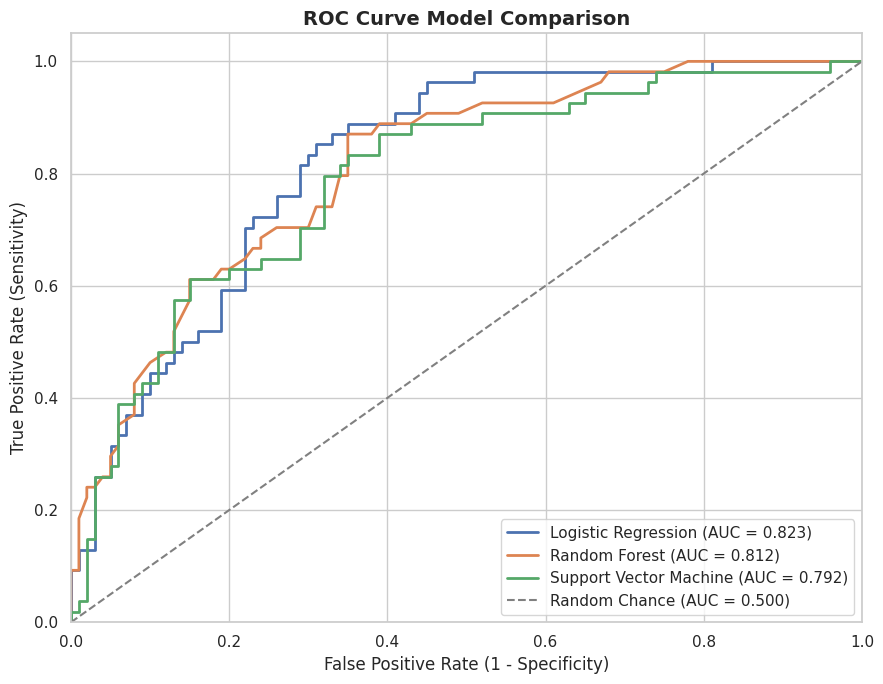


================ EVALUATION METRICS ================
                        Accuracy Precision    Recall  F1 Score   ROC-AUC
Logistic Regression     0.714286  0.608696  0.518519      0.56  0.822963
Random Forest            0.75974  0.680851  0.592593  0.633663  0.811759
Support Vector Machine  0.753247      0.66  0.611111  0.634615  0.792407


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


target_column = 'Outcome'
X = pima_df.drop(columns=[target_column])
y = pima_df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining Set Shape: {X_train.shape}")
print(f"Testing Set Shape: {X_test.shape}")


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)


models = {
    "Logistic Regression": (LogisticRegression(random_state=42), True),   # Needs scaled data
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=42), False), # Tree-based (no scaling needed)
    "Support Vector Machine": (SVC(probability=True, random_state=42), True) # Needs probability=True for ROC-AUC
}

results = {}
plt.figure(figsize=(9, 7))


for name, (model, use_scaling) in models.items():

    X_tr = X_train_scaled if use_scaling else X_train
    X_te = X_test_scaled if use_scaling else X_test


    model.fit(X_tr, y_train)


    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]  # Probabilities for class 1

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    results[name] = {
        "Model_Object": model,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }


    fpr, tpr, _ = roc_curve(y_test, y_proba)


    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")


plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Chance (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
plt.title("ROC Curve Model Comparison", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


results_df = pd.DataFrame(results).T.drop(columns=["Model_Object"])
print("\n================ EVALUATION METRICS ================")
print(results_df.round(4))

In [ ]:
import joblib


best_model_name = max(results, key=lambda k: results[k]["ROC-AUC"])
best_model_obj = results[best_model_name]["Model_Object"]
best_score = results[best_model_name]["ROC-AUC"]

print("\n================ BEST MODEL SELECTION ================")
print(f" Best Performing Model: {best_model_name}")
print(f" Highest ROC-AUC Score: {best_score:.4f}")


model_filename = "best_classification_model.pkl"
joblib.dump(best_model_obj, model_filename)

print(f"\n Model successfully saved as: '{model_filename}'")


================ BEST MODEL SELECTION ================
 Best Performing Model: Logistic Regression
 Highest ROC-AUC Score: 0.8230

 Model successfully saved as: 'best_classification_model.pkl'
